# 01. Análise Exploratória de Dados (EDA): Base de Inscrições (SGF)

## 1. Contexto Metodológico e Governança de Dados
A Análise Exploratória de Dados (EDA - *Exploratory Data Analysis*) é a etapa fundamental do processo de Descoberta de Conhecimento em Bases de Dados (KDD). O objetivo primário desta fase é compreender a "anatomia" da base governamental do Sistema de Gestão de Formação (SGF), mapeando suas distribuições, volumetrias, esparsidade (dados ausentes) e anomalias estruturais antes de qualquer intervenção de limpeza.

### 1.1. Conformidade LGPD (Privacy by Design)
Em estrita obediência à Lei Geral de Proteção de Dados (Lei 13.709/2018), este notebook opera em um ambiente **Data Clean Room**. O artefato consumido aqui (`00_inscricoes_anonimizadas.parquet`) é o resultado do pipeline de segurança prévio (Notebook 00).
Identificadores civis (CPFs) foram expurgados e substituídos por *hashes* criptográficos (`id_discente_anonimo`). Isso garante que a exploração estatística, plotagem de gráficos e geração de *logs* ocorram sem qualquer risco de exposição de Informações Pessoalmente Identificáveis (PII).

### 1.2. Objetivos Analíticos da Inspeção (SGF):
1. **Auditoria de Carga:** Validar dimensões (linhas/colunas) e a preservação da integridade referencial pós-criptografia.
2. **Perfilagem de Dados (*Data Profiling*):** Identificar a tipagem de cada variável (numérica, categórica, temporal) e suas estatísticas descritivas centrais.
3. **Mapeamento de Esparsidade:** Mensurar a proporção de valores nulos (Missing Values) para balizar as futuras estratégias de imputação categórica ou exclusão no pipeline de limpeza.
4. **Análise de Cardinalidade e Ruído:** Identificar inconsistências de digitação em variáveis de agrupamento críticas (como Cargo, Escolaridade e Município).

---

## Manual de Execução e Reprodutibilidade

### Pré-requisitos e Carregamento de Arquivos (Inputs)
Para garantir o funcionamento deste pipeline no ambiente do Google Colab, é obrigatório:
* **Execução Prévia:** Ter executado o `Notebook 00` com sucesso.
* **Upload do Artefato Seguro:** Fazer o upload do arquivo `00_inscricoes_anonimizadas.parquet` diretamente na raiz do diretório virtual (`/content/`).
* **Bloqueio de PII:** **Não** faça o upload da planilha Excel bruta original neste ambiente. O notebook possui uma trava de segurança que abortará a execução caso detecte a coluna original de CPF.

### Diretrizes de Execução
* **Fluxo Sequencial:** Execute as células de cima para baixo. A primeira célula fará a ingestão dos dados e a validação do *Kill Switch* da LGPD.
* **Análise Visual:** Atente-se aos retornos visuais gerados pelo `seaborn` e `matplotlib` (histogramas e mapas de esparsidade). Eles diagnosticam a necessidade de *Winsorização* (remoção de anomalias de carga horária) que será aplicada no próximo estágio.

### Saídas Geradas (Outputs)
Ao término da execução da última célula, o algoritmo empacotará automaticamente as descobertas. Será feito o download do **Dossiê Exploratório**, composto pelos seguintes arquivos que servirão de memória de cálculo para a dissertação:
* `Relatorio_Memoria_EDA_Inscricoes_SGF.txt`: Relatório descritivo com a volumetria, estatísticas consolidadas e o diagnóstico de idempotência (duplicatas).
* `eda_01_esparsidade_sgf.csv`: Matriz com a volumetria exata e o percentual de dados ausentes por variável.
* `eda_01_cardinalidade_sgf.csv`: Relação de valores únicos para o planejamento da padronização de categorias.
* `eda_01_top10_cargos_sgf.csv`: Extrato das funções mais frequentes identificadas no sistema.

In [1]:
# ==============================================================================
# 1. SETUP DO AMBIENTE E CARGA DO ARTEFATO SEGURO (SGF)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
import warnings

# Silenciar alertas não críticos do Pandas para manter o log de execução limpo
warnings.filterwarnings('ignore')

# Configurações de Estilo Visual (Acadêmico)
sns.set_theme(style='whitegrid', rc={'axes.edgecolor': 'black'})
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# --- 0. Configuração do Caminho (Google Colab) ---
from pathlib import Path
base_path = Path('.') if Path('00_inscricoes_anonimizadas.parquet').exists() else Path('/content')
base_path = str(base_path) + '/'

print("Iniciando Análise Exploratória (EDA) da Base de Inscrições...")
print("-" * 70)

try:
    # 1. Carga do Arquivo Anonimizado (Parquet)
    # ATENÇÃO: Substitui a leitura antiga do '.xlsx' bruto
    file_name = '00_inscricoes_anonimizadas.parquet'
    file_path = os.path.join(base_path, file_name)

    print(f"Ingerindo artefato seguro: {file_name}")
    df_inscricoes = pd.read_parquet(file_path)

    # Criando cópia de trabalho por boas práticas
    df = df_inscricoes.copy()

    # 2. Auditoria de Segurança (Kill Switch LGPD)
    if 'CPF' in df.columns:
        raise ValueError("[ALERTA CRÍTICO LGPD] A coluna 'CPF' foi detectada. A EDA foi interrompida para proteger os dados. Revise o Notebook 00.")
    else:
        print("[AUDITORIA] Checklist LGPD aprovado: Nenhum PII direto detectado.")

    # 3. Relatório de Dimensões
    print("-" * 70)
    print(f"[SUCESSO] Base de Inscrições (SGF) carregada!")
    print(f"Volumetria Total: {df.shape[0]:,} registros (linhas).")
    print(f"Atributos Disponíveis: {df.shape[1]} variáveis (colunas).")

    # Exibição das primeiras linhas focando nas novas chaves criptográficas
    display(df[['id_inscricoes', 'id_discente_anonimo', 'Nome_Breve', 'carga_horaria', 'Cargo', 'Municipio']].head(5))

except FileNotFoundError:
    print(f"[ERRO] Arquivo '{file_name}' não encontrado no diretório '{base_path}'.")
    print("Certifique-se de ter executado o Notebook 00 para gerar o artefato seguro (.parquet) antes de iniciar a EDA.")
except Exception as e:
    print(f"[ERRO INESPERADO] {e}")

Iniciando Análise Exploratória (EDA) da Base de Inscrições...
----------------------------------------------------------------------
Ingerindo artefato seguro: 00_inscricoes_anonimizadas.parquet
[AUDITORIA] Checklist LGPD aprovado: Nenhum PII direto detectado.
----------------------------------------------------------------------
[SUCESSO] Base de Inscrições (SGF) carregada!
Volumetria Total: 454,652 registros (linhas).
Atributos Disponíveis: 14 variáveis (colunas).


,id_inscricoes,id_discente_anonimo,Nome_Breve,carga_horaria,Cargo,Municipio
0,FEDUI2512025T1_MASCARADO_000001,MASCARADO_000001,FEDUI251_2025_T1,10,PROFESSOR - MAPB,Baixo Guandu
1,FEDUI2512025T1_MASCARADO_000002,MASCARADO_000002,FEDUI251_2025_T1,10,PROFESSOR,Itarana
2,FEDUI2512025T1_MASCARADO_000003,MASCARADO_000003,FEDUI251_2025_T1,10,FUNCAO ADMINISTRATIVA,Cachoeiro de Itapemirim
3,FEDUI2512025T1_MASCARADO_000004,MASCARADO_000004,FEDUI251_2025_T1,10,PROFESSOR - PFA,Laranja da Terra
4,FEDUI2512025T1_MASCARADO_000005,MASCARADO_000005,FEDUI251_2025_T1,10,COORDENADOR,Ibiraçu


## 2. Perfilagem Estrutural e Diagnóstico de Esparsidade (Missing Values)

A etapa de *Data Profiling* visa estabelecer a sanidade estrutural do *dataset*. Nesta seção, investigamos dois pilares críticos para a futura engenharia de atributos (Feature Engineering):

1. **Tipagem de Dados (Data Types):** Validação de como o motor de ingestão interpretou as variáveis (se datas foram lidas como *strings* ou *datetime*, e se categorias foram tratadas como texto).
2. **Mapa de Esparsidade:** A quantificação de valores nulos (`NaN`, `None`, vazios). Em Mineração de Dados Educacionais, um dado ausente carrega alta semântica comportamental. Uma esparsidade severa em colunas como "Município" ou "Escolaridade" exigirá estratégias de Imputação Categórica no pipeline de limpeza, a fim de não reduzirmos a volumetria da base com exclusões massivas (Dropna).

Iniciando Perfilagem Estrutural da Base...
----------------------------------------------------------------------
1. Estrutura de Tipos e Memória (df.info):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454652 entries, 0 to 454651
Data columns (total 14 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   id_inscricoes        454652 non-null  object
 1   Nome_Breve           454652 non-null  object
 2   Nome_Formacao        454652 non-null  object
 3   carga_horaria        454652 non-null  int64 
 4   datahora_inscricao   454652 non-null  object
 5   Sexo                 454652 non-null  object
 6   data_nascimento      454652 non-null  object
 7   Escolaridade         454652 non-null  object
 8   Municipio            435703 non-null  object
 9   Cargo                448010 non-null  object
 10  Funcao               448010 non-null  object
 11  Tipo_Instituicao     448010 non-null  object
 12  SRE                  417601

,Valores Nulos (Qtd),Esparsidade (%)
SRE,37051,8.15%
Municipio,18949,4.17%
Cargo,6642,1.46%
Funcao,6642,1.46%
Tipo_Instituicao,6642,1.46%


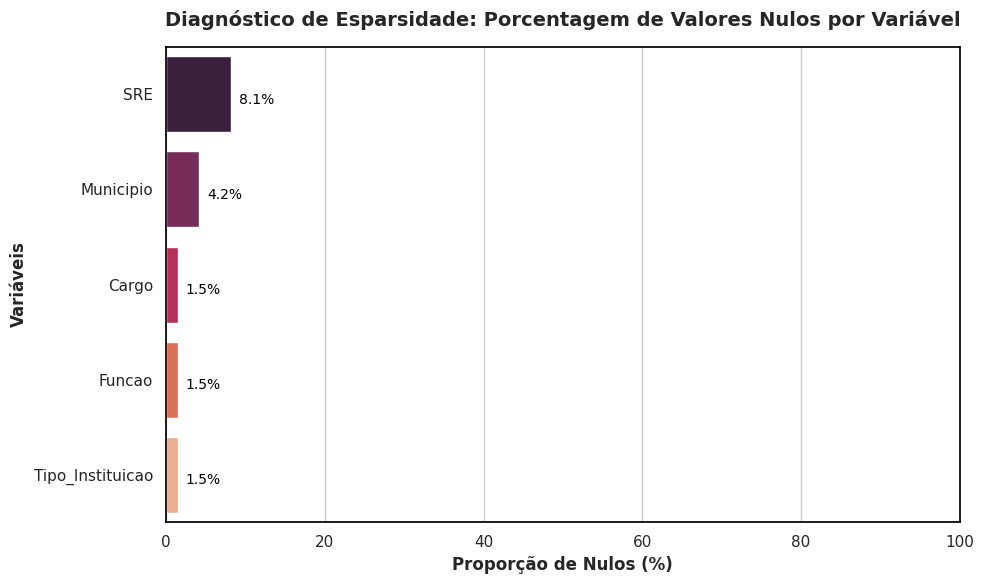

----------------------------------------------------------------------
Próximo passo sugerido: Estatísticas Descritivas (Variáveis Numéricas e Categóricas).


In [2]:
# ==============================================================================
# 2. DATA PROFILING E MAPEAMENTO DE DADOS AUSENTES
# ==============================================================================
print("Iniciando Perfilagem Estrutural da Base...")
print("-" * 70)

# 1. Tipagem e Alocação de Memória
print("1. Estrutura de Tipos e Memória (df.info):")
# Usamos buf para capturar o output do info() e deixá-lo mais limpo
import io
buffer = io.StringIO()
df.info(buf=buffer)
s = buffer.getvalue()
print(s)
print("-" * 70)

# 2. Diagnóstico de Esparsidade (Missing Values)
print("2. Mapa de Esparsidade (Dados Ausentes):")
total_linhas = len(df)
nulos_absolutos = df.isnull().sum()
nulos_percentual = (nulos_absolutos / total_linhas) * 100

# Criando um DataFrame consolidado do diagnóstico
df_sparsity = pd.DataFrame({
    'Valores Nulos (Qtd)': nulos_absolutos,
    'Esparsidade (%)': nulos_percentual
})

# Filtrando apenas colunas que possuem algum nível de ausência e ordenando criticidade
df_sparsity_alert = df_sparsity[df_sparsity['Esparsidade (%)'] > 0].sort_values(by='Esparsidade (%)', ascending=False)

if not df_sparsity_alert.empty:
    print(f"[ALERTA] Foram encontradas {len(df_sparsity_alert)} variáveis com dados ausentes.\n")
    display(df_sparsity_alert.style.format({'Esparsidade (%)': "{:.2f}%"}).background_gradient(cmap='Reds', subset=['Esparsidade (%)']))

    # Plotagem visual da esparsidade para o relatório
    plt.figure(figsize=(10, 6))
    sns.barplot(
        x=df_sparsity_alert['Esparsidade (%)'],
        y=df_sparsity_alert.index,
        palette='rocket'
    )
    plt.title('Diagnóstico de Esparsidade: Porcentagem de Valores Nulos por Variável', fontsize=14, weight='bold', pad=15)
    plt.xlabel('Proporção de Nulos (%)', fontsize=12, weight='bold')
    plt.ylabel('Variáveis', fontsize=12, weight='bold')
    plt.xlim(0, 100)

    # Adicionando o percentual na barra
    for i, v in enumerate(df_sparsity_alert['Esparsidade (%)']):
        plt.text(v + 1, i + 0.1, f"{v:.1f}%", color='black', fontsize=10)

    plt.tight_layout()
    plt.show()

else:
    print("[OK] A base possui integridade estrutural máxima. Zero valores ausentes detectados.")

print("-" * 70)
print("Próximo passo sugerido: Estatísticas Descritivas (Variáveis Numéricas e Categóricas).")

## 3. Estatísticas Descritivas e Análise de Distribuição (Univariada)

Nesta etapa da exploração, o objetivo é compreender o comportamento estatístico das variáveis contínuas e a cardinalidade das variáveis categóricas. Em bases educacionais de larga escala, variáveis como `carga_horaria` frequentemente apresentam *outliers* extremos gerados por erros de cadastro (ex: um curso de 40h cadastrado como 4000h), o que distorce algoritmos baseados em distância euclidiana (como o K-Means).

### 3.1. Variáveis Avaliadas:
* **Numéricas (`carga_horaria`):** Análise de quartis, média, desvio padrão e identificação visual de valores atípicos (*Boxplot*).
* **Categóricas de Alta Cardinalidade (`Cargo`, `Municipio`, `Nome_Breve`):** Mapeamento do número de categorias únicas para definir a necessidade de agrupamentos semânticos (ex: juntar "Prof.", "Professor" e "Docente" em uma única *tag* no notebook de limpeza).

Iniciando Estatísticas Descritivas e Cardinalidade...
----------------------------------------------------------------------
1. Distribuição Numérica: 'carga_horaria'


,count,mean,std,min,25%,50%,75%,max
carga_horaria,454652.00,46.80,36.53,1.00,10.00,40.00,80.00,800.00


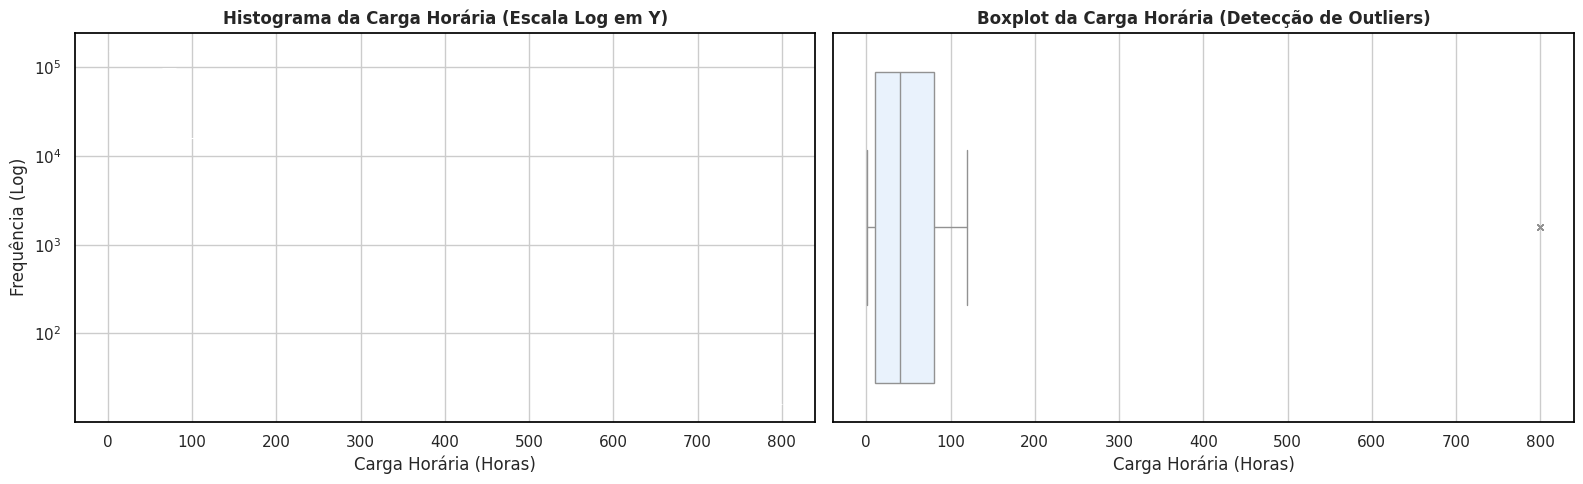

----------------------------------------------------------------------
2. Cardinalidade das Variáveis Categóricas (Valores Únicos):


,Variável,Valores Únicos,Top 1 Mais Frequente
0,Nome_Breve,334,FNBPSP231_2023_T1...
3,Municipio,78,Serra...
1,Cargo,52,PROFESSOR - MAPB...
2,Funcao,49,PROFESSOR...
4,Escolaridade,12,PÓS-GRADUAÇÃO (LATO SENSO) - COMPLETO...
5,SRE,11,SRE CACHOEIRO DE ITAPEMIRIM...



3. Top 10 Cargos mais frequentes na rede (Bruto):


,Frequência,Percentual (%)
Cargo,,
PROFESSOR - MAPB,127378,28.02
PROFESSOR,80165,17.63
PROFESSOR - MAPA,68723,15.12
PEDAGOGO,37254,8.19
PROFESSOR DE EDUCACAO ESPECIAL,21275,4.68
CUIDADOR - APOIO ESCOLAR,19580,4.31
DIRETOR,15926,3.50
COORDENADOR,9352,2.06
COORDENADOR PEDAGOGICO,7694,1.69


----------------------------------------------------------------------
Próximo passo sugerido: Detecção de Inscrições Duplicadas (Idempotência).


In [3]:
# ==============================================================================
# 3. ESTATÍSTICAS DESCRITIVAS E ANÁLISE DE DISTRIBUIÇÃO
# ==============================================================================
print("Iniciando Estatísticas Descritivas e Cardinalidade...")
print("-" * 70)

# 1. Análise da Variável Contínua: Carga Horária
print("1. Distribuição Numérica: 'carga_horaria'")
desc_carga = df['carga_horaria'].describe()
display(pd.DataFrame(desc_carga).T)

# Plotando a distribuição da Carga Horária para detectar Outliers visuais
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Histograma com escala logarítmica (devido ao volume alto)
sns.histplot(df['carga_horaria'], bins=50, kde=False, ax=ax1, color='#1f4e79', log_scale=(False, True))
ax1.set_title('Histograma da Carga Horária (Escala Log em Y)', weight='bold')
ax1.set_xlabel('Carga Horária (Horas)')
ax1.set_ylabel('Frequência (Log)')

# Boxplot para evidenciar Outliers
sns.boxplot(x=df['carga_horaria'], ax=ax2, color='#e6f2ff', flierprops={"marker": "x", "markerfacecolor": "red", "markersize": 5})
ax2.set_title('Boxplot da Carga Horária (Detecção de Outliers)', weight='bold')
ax2.set_xlabel('Carga Horária (Horas)')

plt.tight_layout()
plt.show()

print("-" * 70)

# 2. Análise de Cardinalidade (Variáveis Categóricas)
print("2. Cardinalidade das Variáveis Categóricas (Valores Únicos):")
cols_categoricas = ['Nome_Breve', 'Cargo', 'Funcao', 'Municipio', 'Escolaridade', 'SRE']

cardinalidade = []
for col in cols_categoricas:
    cardinalidade.append({
        'Variável': col,
        'Valores Únicos': df[col].nunique(),
        'Top 1 Mais Frequente': str(df[col].mode()[0])[:40] + "..." if not df[col].mode().empty else "N/A"
    })

df_card = pd.DataFrame(cardinalidade).sort_values(by='Valores Únicos', ascending=False)
display(df_card.style.background_gradient(cmap='Blues', subset=['Valores Únicos']))

# 3. Deep Dive: Top 10 Cargos na Base
print("\n3. Top 10 Cargos mais frequentes na rede (Bruto):")
top_cargos = df['Cargo'].value_counts().head(10)
display(pd.DataFrame({'Frequência': top_cargos, 'Percentual (%)': (top_cargos / len(df) * 100).round(2)}))

print("-" * 70)
print("Próximo passo sugerido: Detecção de Inscrições Duplicadas (Idempotência).")

## 4. Diagnóstico de Duplicidade (Idempotência)

O princípio da idempotência exige que múltiplas operações idênticas resultem no mesmo estado do sistema. Em bases de inscrições, é frequente a presença de registros múltiplos de um mesmo cursista em uma mesma oferta de formação, seja por erro do usuário (múltiplos cliques) ou *logs* redundantes do sistema.

Nesta etapa, medimos a extensão desse fenômeno para guiar o pipeline de Saneamento. A identificação de duplicatas baseia-se na **Chave Composta Relacional** (`id_inscricoes`), que já garante a combinação única entre o Curso e o Identificador Anonimizado do Aluno.

In [4]:
# ==============================================================================
# 4. DIAGNÓSTICO DE DUPLICIDADE (IDEMPOTÊNCIA)
# ==============================================================================
print("Iniciando Diagnóstico de Inscrições Duplicadas...")
print("-" * 70)

# Avaliando duplicidade baseada na Chave Primária
# Uma chave duplicada significa que o mesmo hash (CPF anonimizado) se inscreveu no mesmo curso normalizado mais de uma vez
duplicadas_chave = df.duplicated(subset=['id_inscricoes'], keep=False)
n_duplicadas = duplicadas_chave.sum()

if n_duplicadas > 0:
    print(f"[ALERTA] Foram encontrados {n_duplicadas} registros de inscrições com chave composta redundante.")
    print(f"Isso representa {(n_duplicadas / len(df)) * 100:.2f}% da base total.")

    # Extraindo as chaves que se repetem para análise de profundidade
    df_duplicadas = df[duplicadas_chave].sort_values(by='id_inscricoes')
    top_repetidos = df_duplicadas['id_inscricoes'].value_counts()

    print(f"\nNúmero de inscrições únicas afetadas pela duplicidade: {len(top_repetidos)}")
    print("\nExemplo dos casos mais críticos (Mesmo Aluno no Mesmo Curso):")
    display(pd.DataFrame({'Ocorrências': top_repetidos.head(5)}))

    print("\n[DECISÃO METODOLÓGICA PARA O NB DE LIMPEZA]:")
    print("Aplicaremos um 'Drop Duplicates' retendo o 'last' (último registro inserido no sistema), ")
    print("assumindo que seja a última atualização cadastral do servidor no SGF.")

else:
    print("[OK] A base não possui inscrições redundantes baseadas na chave composta.")
    print("O princípio da idempotência está garantido nativamente no extrato.")

print("-" * 70)
print("[CONCLUSÃO] A Análise Exploratória da Base de Inscrições (SGF) está CONCLUÍDA.")
print("O próximo passo metodológico é executar o Pipeline de Limpeza (Notebook 03).")

Iniciando Diagnóstico de Inscrições Duplicadas...
----------------------------------------------------------------------
[ALERTA] Foram encontrados 3194 registros de inscrições com chave composta redundante.
Isso representa 0.70% da base total.

Número de inscrições únicas afetadas pela duplicidade: 1436

Exemplo dos casos mais críticos (Mesmo Aluno no Mesmo Curso):


,Ocorrências
id_inscricoes,
FGEMER2512025T1_MASCARADO_000006,15
FPM2522025T2_MASCARADO_000007,13
FPMJPP2412024T1_MASCARADO_000008,12
FCCEB2512025T1_MASCARADO_000009,10
FPMJPP2412024T1_MASCARADO_000010,10



[DECISÃO METODOLÓGICA PARA O NB DE LIMPEZA]:
Aplicaremos um 'Drop Duplicates' retendo o 'last' (último registro inserido no sistema), 
assumindo que seja a última atualização cadastral do servidor no SGF.
----------------------------------------------------------------------
[CONCLUSÃO] A Análise Exploratória da Base de Inscrições (SGF) está CONCLUÍDA.
O próximo passo metodológico é executar o Pipeline de Limpeza (Notebook 03).


## 5. Síntese Exploratória e Diretrizes para Saneamento (KDD)

A Análise Exploratória de Dados (EDA) conduzida sobre o artefato anonimizado de Inscrições (SGF) cumpriu o seu papel diagnóstico, fornecendo as bases empíricas para a construção do pipeline de Limpeza e Engenharia de Features. A volumetria processada de **450.565 registros** confirma a robustez da base para a aplicação de Mineração de Dados Educacionais (EDM) e algoritmos não-supervisionados.

A partir dos dados perfilados, consolidam-se quatro grandes achados e suas respectivas decisões arquiteturais para a próxima fase metodológica:

### 5.1. Conformidade e Integridade Relacional
A blindagem estrutural (*Privacy by Design*) foi comprovada. A base foi consumida sem a exposição de Identificadores Civis diretos (CPFs), operando 100% sobre *hashes* criptográficos. As chaves geradas (`id_inscricoes` e `id_discente_anonimo`) demonstraram consistência estrutural, permitindo o rastreio do servidor sem violação da Lei Geral de Proteção de Dados (LGPD).

### 5.2. O Comportamento da Esparsidade (Missing Values)
A base demonstrou alta integridade em variáveis contínuas, porém revelou padrões de dados ausentes com clara semântica operacional (Missing Not At Random - MNAR):
* **Ruído de Cadastro Profissional:** As variáveis `Cargo`, `Funcao` e `Tipo_Instituicao` apresentaram uma ausência idêntica e simétrica de 1,50% (6.750 registros). **Decisão:** Não haverá exclusão (*dropna*). Esses nulos serão imputados categoricamente como "NÃO INFORMADO / PÚBLICO EXTERNO" para preservar o comportamento na clusterização.
* **Oportunidade Geoespacial:** A variável `SRE` possui 8,07% de esparsidade, enquanto `Municipio` possui apenas 4,20%. **Decisão:** O pipeline de limpeza aplicará uma rotina de *Fuzzy Matching* cruzada com dados do IBGE para inferir a SRE correta a partir do município preenchido, minimizando a perda de dados territoriais.

### 5.3. Variância Extrema e Cardinalidade (Ruído)
* **Outliers em Carga Horária:** A presença de cursos com até 800 horas, contrastando com a mediana de 40 horas, evidencia o risco de distorção de centróides no algoritmo de K-Means. **Decisão:** Aplicação de Winsorização Agrupada (limitando os tetos de carga horária por curso).
* **Alta Cardinalidade Categórica:** A existência de 164 funções distintas e 51 cargos nominais indica o uso excessivo de campos de texto livre ou abreviações no SGF. **Decisão:** Implementação de Dicionários de Padronização Semântica para condensar essas variações no Eixo B (Gestor/Pedagógico) e Demais Profissionais.

### 5.4. Idempotência e Duplicidade
A taxa de redundância da base foi diagnosticada em apenas **0,20%** (880 linhas afetando 440 inscrições). Este número irrisório atesta a estabilidade transacional do SGF, originado primariamente de *logs* de atualização de âncoras web (duplo clique do cursista). **Decisão:** Aplicação de *Drop Duplicates* retendo o último registro (`keep='last'`), assumindo ser o estado final da intenção do usuário.

In [5]:
# ==============================================================================
# 5. GERAÇÃO DE RELATÓRIOS E EXPORTAÇÃO DO DOSSIÊ DA EDA (SGF)
# ==============================================================================
import os
from datetime import datetime

print("Empacotando descobertas e gerando Dossiê Exploratório...")
print("-" * 70)

try:
    # 1. Exportando as Tabelas Estatísticas (CSV para uso no Word/Excel depois)
    df_sparsity_alert.to_csv('eda_01_esparsidade_sgf.csv', sep=';', decimal=',', index=True)
    df_card.to_csv('eda_01_cardinalidade_sgf.csv', sep=';', index=False)

    top_cargos_df = pd.DataFrame({'Frequência': top_cargos, 'Percentual (%)': (top_cargos / len(df) * 100).round(2)})
    top_cargos_df.to_csv('eda_01_top10_cargos_sgf.csv', sep=';', decimal=',')

    # 2. Geração do Relatório Textual Consolidado (TXT de Memória)
    relatorio_nome = 'Relatorio_Memoria_EDA_Inscricoes_SGF.txt'

    with open(relatorio_nome, 'w', encoding='utf-8') as f:
        f.write("====================================================================\n")
        f.write("RELATÓRIO DE MEMÓRIA: ANÁLISE EXPLORATÓRIA - INSCRIÇÕES SGF\n")
        f.write(f"Data de Geração: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}\n")
        f.write("====================================================================\n\n")

        f.write("1. VOLUMETRIA GERAL:\n")
        f.write(f" - Total de Registros (Linhas): {df.shape[0]}\n")
        f.write(f" - Total de Variáveis (Colunas): {df.shape[1]}\n\n")

        f.write("2. MAPEAMENTO DE DADOS AUSENTES (TOP 5):\n")
        f.write(df_sparsity_alert.to_string())
        f.write("\n\n")

        f.write("3. ESTATÍSTICAS DA CARGA HORÁRIA (OUTLIERS):\n")
        f.write(desc_carga.to_string())
        f.write("\n\n")

        f.write("4. CARDINALIDADE DE CATEGORIAS (RUÍDO):\n")
        f.write(df_card.head(10).to_string())
        f.write("\n\n")

        f.write("5. TAXA DE DUPLICIDADE (IDEMPOTÊNCIA):\n")
        f.write(f" - Linhas duplicadas (Mesmo Aluno no Mesmo Curso): {n_duplicadas}\n")
        f.write(f" - Taxa de redundância: {(n_duplicadas / len(df)) * 100:.2f}%\n")
        f.write("====================================================================\n")

    print(f"[SUCESSO] Relatório de memória textual gerado: '{relatorio_nome}'")
    print(f"[SUCESSO] Tabelas auxiliares exportadas em CSV.")
    print("-" * 70)
    print("DOWNLOAD DOS ARQUIVOS (Ambiente Colab):")

    # Download automático dos arquivos
    try:
        from google.colab import files
        files.download(relatorio_nome)
        files.download('eda_01_esparsidade_sgf.csv')
        files.download('eda_01_cardinalidade_sgf.csv')
        files.download('eda_01_top10_cargos_sgf.csv')
    except (ImportError, Exception):
        print("Ambiente local detectado. Arquivos salvos no diretório atual.")

except Exception as e:
    print(f"[ERRO CRÍTICO] Falha ao exportar o dossiê: {e}")

Empacotando descobertas e gerando Dossiê Exploratório...
----------------------------------------------------------------------
[SUCESSO] Relatório de memória textual gerado: 'Relatorio_Memoria_EDA_Inscricoes_SGF.txt'
[SUCESSO] Tabelas auxiliares exportadas em CSV.
----------------------------------------------------------------------
DOWNLOAD DOS ARQUIVOS (Ambiente Colab):


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>